In [27]:
from __future__ import annotations

import argparse
import random
import statistics
import sys
import time
import traceback

import matplotlib.pyplot as plt

%matplotlib inline

In [28]:
# ---------------------------------------------------------------------------
# 1. Простые сортировки со счётчиками (сортируют КОПИЮ входа, вход не меняют)
#    Каждая функция возвращает кортеж: (отсортированный список,
#    число сравнений ключей, число обменов/перемещений элементов).
# ---------------------------------------------------------------------------


def bubble_sort(a: list) -> tuple[list, int, int]:
    """Сортировка пузырьком. Ожидаемая сложность: TODO (обосновать в отчёте).

    Подсказка: досрочный выход, если за проход не было ни одного обмена, —
    именно он даёт лучший случай на упорядоченном входе.
    """
    # TODO: реализовать; считать сравнения и обмены
    arr = list(a)
    n = len(arr)
    comparisons = 0
    swaps = 0
    for i in range(n):
        swapped = False
        for j in range(0, n - 1 - i):
            comparisons += 1
            if arr[j] > arr[j + 1]:
                arr[j], arr[j + 1] = arr[j + 1], arr[j]
                swaps += 1
                swapped = True
        if not swapped:
            break
    return arr, comparisons, swaps


def insertion_sort(a: list) -> tuple[list, int, int]:
    """Сортировка вставками. Ожидаемая сложность: TODO (лучший/худший случаи)."""
    # TODO: реализовать; считать сравнения и перемещения (сдвиги)
    arr = list(a)
    n = len(arr)
    comparisons = 0
    moves = 0
    for i in range(1, n):
        key = arr[i]
        j = i - 1
        while j >= 0:
            comparisons += 1
            if arr[j] > key:
                arr[j + 1] = arr[j]
                moves += 1
                j -= 1
            else:
                break
        arr[j + 1] = key
    return arr, comparisons, moves


def selection_sort(a: list) -> tuple[list, int, int]:
    """Сортировка выбором. Ожидаемая сложность: TODO (почему не зависит от входа?)."""
    # TODO: реализовать; считать сравнения и обмены
    arr = list(a)
    n = len(arr)
    comparisons = 0
    swaps = 0
    for i in range(n - 1):
        min_idx = i
        for j in range(i + 1, n):
            comparisons += 1
            if arr[j] < arr[min_idx]:
                min_idx = j
        if min_idx != i:
            arr[i], arr[min_idx] = arr[min_idx], arr[i]
            swaps += 1
    return arr, comparisons, swaps

In [29]:
# ---------------------------------------------------------------------------
# 2. QuickSort с рандомизированным опорным элементом
# ---------------------------------------------------------------------------


def quick_sort(a: list, rng: random.Random | None = None) -> list:
    """QuickSort с выбором опорного через rng.randrange. Возвращает новый список.

    Ожидаемая сложность: в среднем TODO, в худшем случае TODO (обосновать
    в отчёте, объяснить роль рандомизации). rng передаётся снаружи, чтобы
    запуск был воспроизводим по seed варианта.
    """
    if rng is None:
        rng = random.Random()
    # TODO: реализовать (рекурсивно или циклом со стеком);
    # TODO: опорный элемент — a[rng.randrange(lo, hi)], не первый и не последний.
    arr = list(a)

    def _qsort(lo: int, hi: int) -> None:
        while hi - lo > 1:
            pivot_idx = rng.randrange(lo, hi)
            pivot = arr[pivot_idx]
            i = lo
            j = hi - 1
            while i <= j:
                while arr[i] < pivot:
                    i += 1
                while arr[j] > pivot:
                    j -= 1
                if i <= j:
                    arr[i], arr[j] = arr[j], arr[i]
                    i += 1
                    j -= 1

            # Хвостовая рекурсия: сначала рекурсивно сортируем меньшую часть,
            # а большую обрабатываем на следующей итерации цикла.
            # Это гарантирует предельную глубину стека <= log2(n).
            left_len = (j + 1) - lo
            right_len = hi - i
            if left_len < right_len:
                if lo < j + 1:
                    _qsort(lo, j + 1)
                lo = i
            else:
                if i < hi:
                    _qsort(i, hi)
                hi = j + 1

    _qsort(0, len(arr))
    return arr

In [30]:
# ---------------------------------------------------------------------------
# 3. Демонстрация стабильности на парах (ключ, метка)
# ---------------------------------------------------------------------------


def stability_demo() -> None:
    """Показать, какие из четырёх сортировок стабильны.

    План: взять массив пар (ключ, метка) с повторяющимися ключами, например
    [(2, "a"), (1, "b"), (2, "c"), (1, "d")], отсортировать каждой сортировкой
    по ключу (сравнение только по p[0]!) и напечатать порядок меток при равных
    ключах. Вывод о стабильности каждой сортировки включить в отчёт.
    """
    # TODO: подготовить пары, прогнать все четыре сортировки, напечатать итог
    class _Item:
        __slots__ = ("key", "label")

        def __init__(self, key: int, label: str) -> None:
            self.key = key
            self.label = label

        def __lt__(self, other: _Item) -> bool:
            return self.key < other.key

        def __gt__(self, other: _Item) -> bool:
            return self.key > other.key

        def __le__(self, other: _Item) -> bool:
            return self.key <= other.key

        def __ge__(self, other: _Item) -> bool:
            return self.key >= other.key

        def __repr__(self) -> str:
            return f"({self.key}, '{self.label}')"

    raw_pairs = [(2, "a"), (1, "b"), (2, "c"), (1, "d")]
    print(f"Исходный порядок: {raw_pairs}\n")

    sorts = [
        ("bubble_sort", lambda a: bubble_sort(a)[0]),
        ("insertion_sort", lambda a: insertion_sort(a)[0]),
        ("selection_sort", lambda a: selection_sort(a)[0]),
        ("quick_sort", lambda a: quick_sort(a, random.Random(0))),
    ]

    for name, sort_fn in sorts:
        items = [_Item(k, v) for k, v in raw_pairs]
        sorted_items = sort_fn(items)
        result = [(item.key, item.label) for item in sorted_items]

        labels_k1 = [item.label for item in sorted_items if item.key == 1]
        labels_k2 = [item.label for item in sorted_items if item.key == 2]

        is_stable = (labels_k1 == ["b", "d"] and labels_k2 == ["a", "c"])
        verdict = "СТАБИЛЬНА" if is_stable else "НЕСТАБИЛЬНА"
        print(f"  {name:<15}: {result} -> {verdict}")


stability_demo()

Исходный порядок: [(2, 'a'), (1, 'b'), (2, 'c'), (1, 'd')]

  bubble_sort    : [(1, 'b'), (1, 'd'), (2, 'a'), (2, 'c')] -> СТАБИЛЬНА
  insertion_sort : [(1, 'b'), (1, 'd'), (2, 'a'), (2, 'c')] -> СТАБИЛЬНА
  selection_sort : [(1, 'b'), (1, 'd'), (2, 'c'), (2, 'a')] -> НЕСТАБИЛЬНА
  quick_sort     : [(1, 'd'), (1, 'b'), (2, 'a'), (2, 'c')] -> НЕСТАБИЛЬНА


In [31]:
# ---------------------------------------------------------------------------
# 4. Классы входов (данные по варианту, детерминированно по seed)
# ---------------------------------------------------------------------------


def make_inputs(n: int, seed: int) -> dict[str, list[int]]:
    """Три класса входов размера n: упорядоченный, случайный, обратный."""
    rng = random.Random(seed + n)  # свой поток для каждого размера
    data = [rng.randint(-1_000_000, 1_000_000) for _ in range(n)]
    return {
        "упорядоченный": sorted(data),
        "случайный": data,
        "обратный": sorted(data, reverse=True),
    }


# ---------------------------------------------------------------------------
# 5. Верификация (шаги 1–3 методики docs/ai-verification.md)
# ---------------------------------------------------------------------------

ALGORITHMS = {
    "bubble_sort": lambda a: bubble_sort(a)[0],
    "insertion_sort": lambda a: insertion_sort(a)[0],
    "selection_sort": lambda a: selection_sort(a)[0],
    "quick_sort": lambda a: quick_sort(a, random.Random(0)),
}


def is_sorted(a: list) -> bool:
    """Инвариант 1: неубывающий порядок элементов."""
    return all(a[i] <= a[i + 1] for i in range(len(a) - 1))


class SelfCheckError(Exception):
    """Нарушен контракт или инвариант реализации."""


def expect(condition: bool, message: str) -> None:
    """Явная проверка вместо assert: assert-ы исчезают при запуске python -O."""
    if not condition:
        raise SelfCheckError(message)


def check_algorithm(fn) -> None:
    """Граничные случаи, инварианты сортировки и сверка с эталоном sorted()."""
    boundary = [
        [],                    # пустой массив
        [7],                   # один элемент
        [5, 5, 5, 5],          # все элементы равны
        [1, 2, 3, 4, 5],       # уже отсортирован
        [5, 4, 3, 2, 1],       # обратный порядок
    ]
    for a in boundary:
        res = fn(list(a))
        expect(isinstance(res, list), f"на {a} возвращён {type(res).__name__}, а не список")
        expect(is_sorted(res), f"нарушен порядок на {a}: получено {res}")
        expect(sorted(res) == sorted(a), f"не перестановка входа {a}: получено {res}")

    # Сверка с эталоном из стандартной библиотеки на сотнях случайных входов.
    rng = random.Random(0)
    for _ in range(300):
        a = [rng.randint(-100, 100) for _ in range(rng.randint(0, 80))]
        res = fn(list(a))
        expect(res == sorted(a), f"расходится с sorted() на {a}: получено {res}")


def check_counters() -> None:
    """Счётчики: у сортировки выбором ровно n*(n-1)/2 сравнений на любом входе."""
    _, comparisons, _ = selection_sort([3, 1, 2, 5, 4])
    expect(comparisons == 10,
           f"selection_sort: неверный счётчик сравнений — {comparisons}, ожидалось 10")


def check_custom_invariants() -> None:
    """Собственные проверки: стабильность алгоритмов и граничные счётчики операций."""
    n = 10
    sorted_arr = list(range(n))

    # 1. BubbleSort на отсортированном: n - 1 сравнений и 0 обменов
    _, cmp_bubble, swaps_bubble = bubble_sort(sorted_arr)
    expect(cmp_bubble == n - 1,
           f"bubble_sort: на упорядоченном входе ожидалось {n - 1} сравнений, получено {cmp_bubble}")
    expect(swaps_bubble == 0,
           f"bubble_sort: на упорядоченном входе ожидалось 0 обменов, получено {swaps_bubble}")

    # 2. InsertionSort: лучший случай (n - 1 сравнений, 0 сдвигов)
    _, cmp_ins_best, moves_ins_best = insertion_sort(sorted_arr)
    expect(cmp_ins_best == n - 1,
           f"insertion_sort: на упорядоченном входе ожидалось {n - 1} сравнений, получено {cmp_ins_best}")
    expect(moves_ins_best == 0,
           f"insertion_sort: на упорядоченном входе ожидалось 0 сдвигов, получено {moves_ins_best}")

    # 3. InsertionSort: худший случай (обратный массив, n*(n-1)//2 сравнений и сдвигов)
    rev_arr = list(range(n, 0, -1))
    expected_worst = n * (n - 1) // 2
    _, cmp_ins_worst, moves_ins_worst = insertion_sort(rev_arr)
    expect(cmp_ins_worst == expected_worst,
           f"insertion_sort: на обратном входе ожидалось {expected_worst} сравнений, получено {cmp_ins_worst}")
    expect(moves_ins_worst == expected_worst,
           f"insertion_sort: на обратном входе ожидалось {expected_worst} сдвигов, получено {moves_ins_worst}")

    # 4. Проверка стабильности на парах (ключ, метка)
    class _Pair:
        __slots__ = ("k", "v")

        def __init__(self, k: int, v: str) -> None:
            self.k = k
            self.v = v

        def __lt__(self, o: _Pair) -> bool:
            return self.k < o.k

        def __gt__(self, o: _Pair) -> bool:
            return self.k > o.k

        def __le__(self, o: _Pair) -> bool:
            return self.k <= o.k

        def __ge__(self, o: _Pair) -> bool:
            return self.k >= o.k

    pairs = [_Pair(2, "a"), _Pair(1, "b"), _Pair(2, "c"), _Pair(1, "d")]

    b_res = bubble_sort(pairs)[0]
    expect([p.v for p in b_res if p.k == 2] == ["a", "c"], "bubble_sort должен быть стабилен")

    ins_res = insertion_sort(pairs)[0]
    expect([p.v for p in ins_res if p.k == 2] == ["a", "c"], "insertion_sort должен быть стабилен")

    sel_res = selection_sort(pairs)[0]
    expect([p.v for p in sel_res if p.k == 2] == ["c", "a"], "selection_sort должен быть нестабилен")


def self_check() -> None:
    """Все проверки по разделам; при любой ошибке замеры не выполняются."""
    # fn=fn фиксирует функцию текущего шага цикла (иначе все лямбды увидят последнюю)
    checks = [(name, lambda fn=fn: check_algorithm(fn)) for name, fn in ALGORITHMS.items()]
    checks.append(("счётчики", check_counters))
    checks.append(("собственные проверки", check_custom_invariants))
    failed = 0
    print("self_check:")
    for name, check in checks:
        try:
            check()
        except NotImplementedError as err:
            where = traceback.extract_tb(err.__traceback__)[-1].name
            print(f"  {name}: не реализовано — {where} (TODO)")
            failed += 1
        except SelfCheckError as err:
            print(f"  {name}: ОШИБКА — {err}")
            failed += 1
        except Exception:  # noqa: BLE001 — падение реализации тоже результат проверки
            print(f"  {name}: ИСКЛЮЧЕНИЕ")
            traceback.print_exc(file=sys.stdout)
            failed += 1
        else:
            print(f"  {name}: OK")
    # TODO: добавить собственные проверки (стабильность, счётчики пузырька и вставок)
    #       и описать их в отчёте.
    if failed:
        raise SystemExit(f"self_check: не пройдено разделов — {failed}; "
                         f"замеры выполняются только после всех проверок.")
    print("self_check: OK")


self_check()

self_check:
  bubble_sort: OK
  insertion_sort: OK
  selection_sort: OK
  quick_sort: OK
  счётчики: OK
  собственные проверки: OK
self_check: OK


In [32]:
# ---------------------------------------------------------------------------
# 6. Бенчмарк (методика — docs/reproducibility.md)
# ---------------------------------------------------------------------------

SIZES_QUADRATIC = [500, 1_000, 2_000, 4_000, 8_000]     # для простых сортировок
SIZES_QUICK = [1_000, 3_000, 10_000, 30_000, 100_000]   # для QuickSort
REPEATS = 5


def bench(fn, data: list) -> float:
    """Медиана времени выполнения fn(копия data) по REPEATS запускам, с прогревом."""
    fn(list(data))  # прогрев — не учитывается
    times = []
    for _ in range(REPEATS):
        arg = list(data)  # свежая копия: сортировка не должна получать свой результат
        t0 = time.perf_counter()
        fn(arg)
        times.append(time.perf_counter() - t0)
    return statistics.median(times)


def run_benchmarks(seed: int) -> dict:
    """Замеры всех алгоритмов на трёх классах входов; результат — таблица в stdout."""
    plans = [
        ("bubble_sort", ALGORITHMS["bubble_sort"], SIZES_QUADRATIC),
        ("insertion_sort", ALGORITHMS["insertion_sort"], SIZES_QUADRATIC),
        ("selection_sort", ALGORITHMS["selection_sort"], SIZES_QUADRATIC),
        ("quick_sort", lambda a: quick_sort(a, random.Random(seed)), SIZES_QUICK),
    ]

    timing_results: dict[str, dict[str, list[tuple[int, float]]]] = {}
    counter_results: dict[str, dict[str, list[dict[str, int]]]] = {
        "bubble_sort": {"упорядоченный": [], "случайный": [], "обратный": []},
        "insertion_sort": {"упорядоченный": [], "случайный": [], "обратный": []},
        "selection_sort": {"упорядоченный": [], "случайный": [], "обратный": []},
    }

    # Сбор точных значений счётчиков операций на малых и средних размерах
    counter_sizes = [10, 50, 100, 500, 1_000]
    for n in counter_sizes:
        inputs_for_counters = make_inputs(n, seed)
        for cls_name, arr in inputs_for_counters.items():
            _, b_cmp, b_swp = bubble_sort(arr)
            counter_results["bubble_sort"][cls_name].append(
                {"n": n, "cmp": b_cmp, "ops": b_swp}
            )

            _, i_cmp, i_mov = insertion_sort(arr)
            counter_results["insertion_sort"][cls_name].append(
                {"n": n, "cmp": i_cmp, "ops": i_mov}
            )

            _, s_cmp, s_swp = selection_sort(arr)
            counter_results["selection_sort"][cls_name].append(
                {"n": n, "cmp": s_cmp, "ops": s_swp}
            )

    # Основные замеры времени по трем классам входов
    for name, fn, sizes in plans:
        print(f"\n{name}:")
        timing_results[name] = {"упорядоченный": [], "случайный": [], "обратный": []}
        for n in sizes:
            for cls, data in make_inputs(n, seed).items():
                t = bench(fn, data)
                timing_results[name][cls].append((n, t))
                print(f"  n={n:>7}  вход={cls:<13} t={t:.6f} c")

    # TODO: построить log-log графики (matplotlib) по классам входов;
    # TODO: сопоставить наклоны с O(n^2) и O(n log n), объяснить расхождения
    #       (в т. ч. лучший случай вставок и поведение пузырька на упорядоченном входе);
    # TODO: включить в отчёт таблицы счётчиков сравнений/обменов.

    return {
        "timings": timing_results,
        "counters": counter_results,
    }

# Запуск сбора данных и замеров под твой вариант
VARIANT = 13
SEED = 30 + VARIANT
random.seed(SEED)
# Запуск сбора данных и замеров
benchmark_data = run_benchmarks(SEED)


bubble_sort:
  n=    500  вход=упорядоченный t=0.000013 c
  n=    500  вход=случайный     t=0.005695 c
  n=    500  вход=обратный      t=0.006842 c
  n=   1000  вход=упорядоченный t=0.000030 c
  n=   1000  вход=случайный     t=0.024230 c
  n=   1000  вход=обратный      t=0.030846 c
  n=   2000  вход=упорядоченный t=0.000067 c
  n=   2000  вход=случайный     t=0.102039 c
  n=   2000  вход=обратный      t=0.122610 c
  n=   4000  вход=упорядоченный t=0.000136 c
  n=   4000  вход=случайный     t=0.408673 c
  n=   4000  вход=обратный      t=0.504090 c
  n=   8000  вход=упорядоченный t=0.000265 c
  n=   8000  вход=случайный     t=1.633257 c
  n=   8000  вход=обратный      t=2.012348 c

insertion_sort:
  n=    500  вход=упорядоченный t=0.000020 c
  n=    500  вход=случайный     t=0.002973 c
  n=    500  вход=обратный      t=0.005725 c
  n=   1000  вход=упорядоченный t=0.000045 c
  n=   1000  вход=случайный     t=0.012408 c
  n=   1000  вход=обратный      t=0.022780 c
  n=   2000  вход=упоряд

ЭМПИРИЧЕСКИЕ НАКЛОНЫ В ОСЯХ LOG-LOG (ОЦЕНКА ПОКАЗАТЕЛЯ СТЕПЕНИ k):

Класс входа: УПОРЯДОЧЕННЫЙ
  bubble_sort    : наклон = 1.08
  insertion_sort : наклон = 1.06
  selection_sort : наклон = 2.03
  quick_sort     : наклон = 1.19

Класс входа: СЛУЧАЙНЫЙ
  bubble_sort    : наклон = 2.04
  insertion_sort : наклон = 1.99
  selection_sort : наклон = 2.04
  quick_sort     : наклон = 1.10

Класс входа: ОБРАТНЫЙ
  bubble_sort    : наклон = 2.04
  insertion_sort : наклон = 2.00
  selection_sort : наклон = 2.04
  quick_sort     : наклон = 1.16


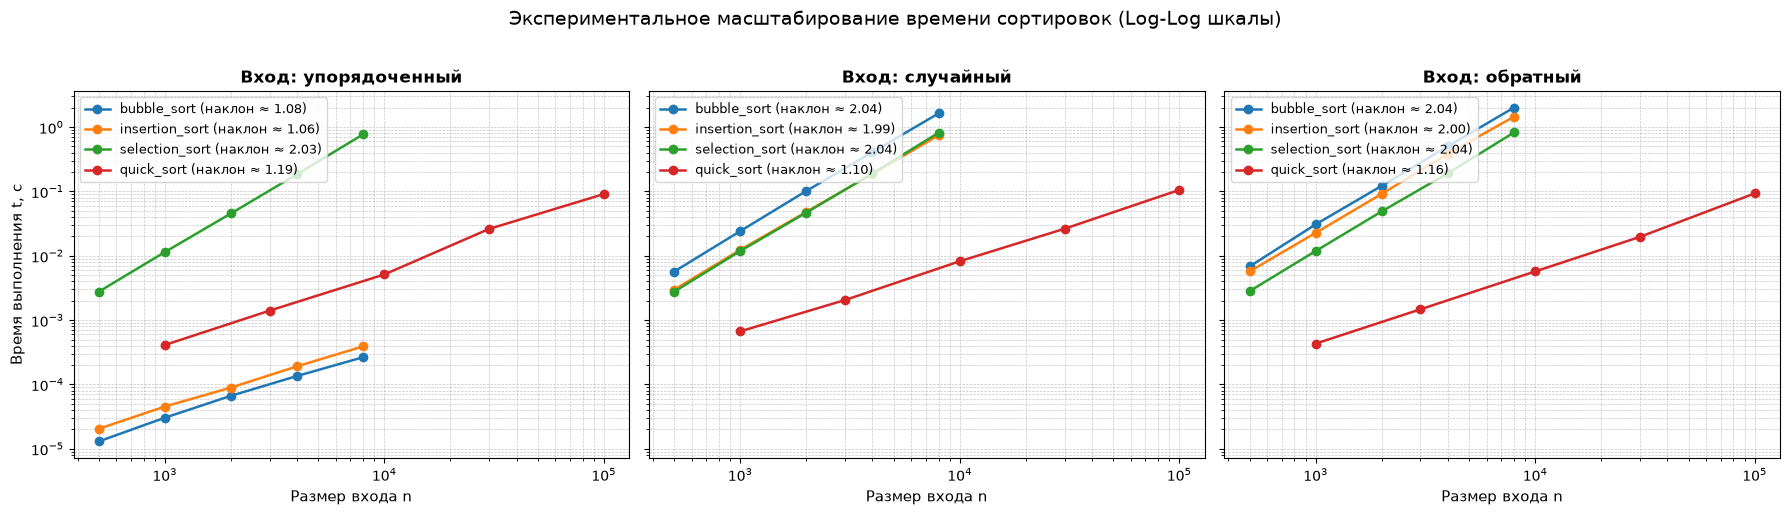


ТАБЛИЦЫ СЧЁТЧИКОВ ОПЕРАЦИЙ (СРАВНЕНИЯ / ПЕРЕМЕЩЕНИЯ И ОБМЕНЫ):

Алгоритм: bubble_sort
     n |     Упорядоченный     |       Случайный       |       Обратный       
       |    Сравн.     обмены |    Сравн.     обмены |    Сравн.     обмены
------------------------------------------------------------------------------
    10 |         9          0 |        39         19 |        45         45
    50 |        49          0 |      1134        606 |      1225       1225
   100 |        99          0 |      4940       2314 |      4950       4950
   500 |       499          0 |    124597      64637 |    124750     124750
  1000 |       999          0 |    499065     257721 |    499500     499500

Алгоритм: insertion_sort
     n |     Упорядоченный     |       Случайный       |       Обратный       
       |    Сравн.     сдвиги |    Сравн.     сдвиги |    Сравн.     сдвиги
------------------------------------------------------------------------------
    10 |         9          0 |        

In [ ]:
import math

# ---------------------------------------------------------------------------
# 7. Визуализация и анализ счётчиков
# ---------------------------------------------------------------------------


def log_log_slope(points: list[tuple[int, float]]) -> float:
    """Наклон прямой в осях (log n, log t) — оценка показателя степени."""
    xs = [math.log10(n) for n, _ in points]
    ys = [math.log10(t) for _, t in points]
    mx, my = sum(xs) / len(xs), sum(ys) / len(ys)
    denom = sum((x - mx) ** 2 for x in xs)
    if denom == 0:
        return 0.0
    return sum((x - mx) * (y - my) for x, y in zip(xs, ys)) / denom


timings = benchmark_data["timings"]
counters = benchmark_data["counters"]
classes = ["упорядоченный", "случайный", "обратный"]
algos = ["bubble_sort", "insertion_sort", "selection_sort", "quick_sort"]
colors = {
    "bubble_sort": "#1f77b4",
    "insertion_sort": "#ff7f0e",
    "selection_sort": "#2ca02c",
    "quick_sort": "#d62728",
}

print("=" * 78)
print("ЭМПИРИЧЕСКИЕ НАКЛОНЫ В ОСЯХ LOG-LOG (ОЦЕНКА ПОКАЗАТЕЛЯ СТЕПЕНИ k):")
print("=" * 78)
for cls in classes:
    print(f"\nКласс входа: {cls.upper()}")
    for name in algos:
        slope = log_log_slope(timings[name][cls])
        print(f"  {name:<15}: наклон = {slope:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, cls in zip(axes, classes):
    for name in algos:
        points = timings[name][cls]
        ns = [pt[0] for pt in points]
        ts = [pt[1] for pt in points]
        slope = log_log_slope(points)
        ax.plot(
            ns,
            ts,
            marker="o",
            linewidth=1.8,
            color=colors[name],
            label=f"{name} (наклон ≈ {slope:.2f})",
        )

    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xlabel("Размер входа n", fontsize=11)
    ax.set_title(f"Вход: {cls}", fontsize=12, fontweight="bold")
    ax.grid(True, which="both", linestyle="--", linewidth=0.5, alpha=0.7)
    ax.legend(fontsize=9, loc="upper left")

axes[0].set_ylabel("Время выполнения t, с", fontsize=11)
fig.suptitle("Экспериментальное масштабирование времени сортировок (Log-Log шкалы)", fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig("lab03_sorts_loglog.png", dpi=150, bbox_inches="tight")
plt.show()

print("\n" + "=" * 78)
print("ТАБЛИЦЫ СЧЁТЧИКОВ ОПЕРАЦИЙ (СРАВНЕНИЯ / ПЕРЕМЕЩЕНИЯ И ОБМЕНЫ):")
print("=" * 78)

for name in ("bubble_sort", "insertion_sort", "selection_sort"):
    op_label = "сдвиги" if name == "insertion_sort" else "обмены"
    print(f"\nАлгоритм: {name}")
    print(f"{'n':>6} | {'Упорядоченный':^21} | {'Случайный':^21} | {'Обратный':^21}")
    print(f"{'':>6} | {'Сравн.':>9} {' ' + op_label:>10} | {'Сравн.':>9} {' ' + op_label:>10} | {'Сравн.':>9} {' ' + op_label:>10}")
    print("-" * 78)

    data_sorted = counters[name]["упорядоченный"]
    data_rand = counters[name]["случайный"]
    data_rev = counters[name]["обратный"]

    for row_s, row_r, row_rev in zip(data_sorted, data_rand, data_rev):
        n_val = row_s["n"]
        s_cmp, s_ops = row_s["cmp"], row_s["ops"]
        r_cmp, r_ops = row_r["cmp"], row_r["ops"]
        rev_cmp, rev_ops = row_rev["cmp"], row_rev["ops"]
        print(
            f"{n_val:>6} | {s_cmp:>9} {s_ops:>10} | {r_cmp:>9} {r_ops:>10} | {rev_cmp:>9} {rev_ops:>10}"
        )